# Miscellaneous plots

## Stellar mass distribution

Each galaxy contributes once. The histogram uses 0.25-dex bins in log₁₀ stellar mass.
Run the data-processing notebook first to build the selected galaxy properties table.

C:\Users\anton\AppData\Local\Temp\ipykernel_14576\3932121301.py:12: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  masses = properties.set_index("galaxy", verify_integrity=True)["stellar_mass_msun"]


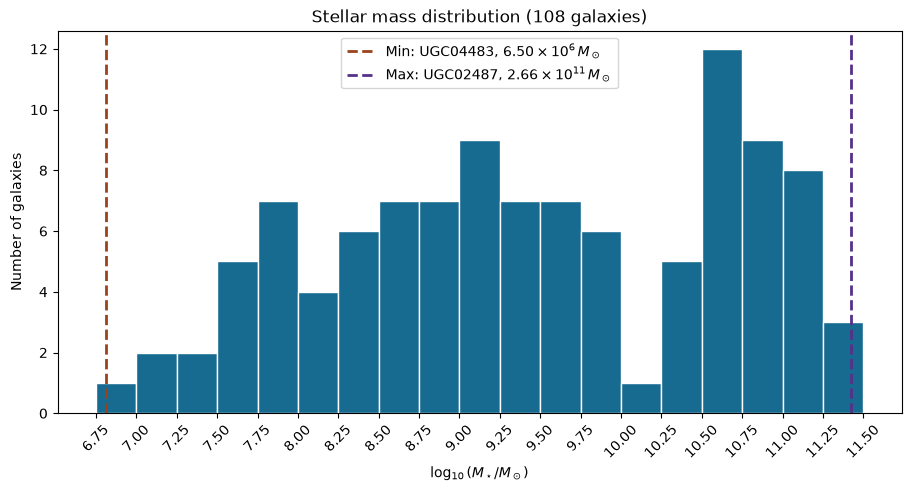

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "utils" / "data_loading.py").is_file()
)
properties = pd.read_csv(PROJECT_ROOT / "data/processed/selected_galaxy_properties.csv")
masses = properties.set_index("galaxy", verify_integrity=True)["stellar_mass_msun"]
if masses.empty or not np.isfinite(masses).all() or (masses <= 0).any():
    raise ValueError("The selected sample must contain finite, positive stellar masses.")

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
log_masses = np.log10(masses)
bin_width = 0.25
first_edge = int(np.floor(log_masses.min() / bin_width))
last_edge = int(np.floor(log_masses.max() / bin_width)) + 1
bin_edges = bin_width * np.arange(first_edge, last_edge + 1)
ax.hist(log_masses, bins=bin_edges, color="#176B91", edgecolor="white")
ax.set_xticks(bin_edges, labels=[f"{edge:.2f}" for edge in bin_edges], rotation=45)
for label, galaxy, color in (
    ("Min", masses.idxmin(), "#9B421B"),
    ("Max", masses.idxmax(), "#553189"),
):
    mass = masses.loc[galaxy]
    coefficient, exponent = f"{mass:.2e}".split("e")
    ax.axvline(
        np.log10(mass), color=color, linestyle="--", linewidth=2,
        label=rf"{label}: {galaxy}, ${coefficient}\times 10^{{{int(exponent)}}}\,M_\odot$",
    )
ax.set(
    title=f"Stellar mass distribution ({len(masses)} galaxies)",
    xlabel=r"$\log_{10}(M_\star/M_\odot)$",
    ylabel="Number of galaxies",
)
ax.margins(x=0.05)
ax.legend()
plt.show()